# 2014 — Generative Adversarial Networks (GAN)

**Paper:** Ian Goodfellow et al., *"Generative Adversarial Nets"* (2014).

Two networks play a game:
- the **generator** $G(z)$ turns noise into samples
- the **discriminator** $D(x)$ tries to tell real samples from generated ones

$$\min_G \max_D\ \mathbb E_{x\sim p_{data}}[\log D(x)] + \mathbb E_{z}[\log(1 - D(G(z)))]$$

At the optimum $p_G = p_{data}$. In practice $G$ maximises $\log D(G(z))$ instead (the **non-saturating** loss), which gives stronger gradients early on.

We use the classic **ring of 8 Gaussians** — small enough for a CPU, and it shows the typical GAN failure **mode collapse** clearly.

![Diagram: Generative adversarial network (Goodfellow et al., 2014)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/22_2014_gan.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
def real_batch(n):
    k = torch.randint(0, 8, (n,))
    angle = k.float() * (2 * math.pi / 8)
    centers = torch.stack([torch.cos(angle), torch.sin(angle)], 1) * 2
    return (centers + 0.05 * torch.randn(n, 2)).to(device)

def mlp(i, o, h=128):
    return nn.Sequential(nn.Linear(i, h), nn.LeakyReLU(0.2), nn.Linear(h, h), nn.LeakyReLU(0.2), nn.Linear(h, o))

G, D = mlp(8, 2).to(device), mlp(2, 1).to(device)
optG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
optD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()

In [3]:
snapshots, B = {}, 256
fixed_z = torch.randn(1000, 8, device=device)
for step in range(1, 6001):
    # --- discriminator step: real -> 1, fake -> 0
    x, z = real_batch(B), torch.randn(B, 8, device=device)
    fake = G(z).detach()
    lossD = bce(D(x), torch.ones(B, 1, device=device)) + bce(D(fake), torch.zeros(B, 1, device=device))
    optD.zero_grad(); lossD.backward(); optD.step()
    # --- generator step (non-saturating): make D call fakes real
    lossG = bce(D(G(torch.randn(B, 8, device=device))), torch.ones(B, 1, device=device))
    optG.zero_grad(); lossG.backward(); optG.step()
    if step in (1, 500, 1500, 3000, 6000):
        with torch.no_grad(): snapshots[step] = G(fixed_z).cpu()
        print(f"step {step:5d}  D loss {lossD.item():.3f}  G loss {lossG.item():.3f}")

step     1  D loss 1.438  G loss 0.650


step   500  D loss 1.118  G loss 0.896


step  1500  D loss 1.036  G loss 1.134


step  3000  D loss 1.034  G loss 1.235


step  6000  D loss 1.089  G loss 1.363


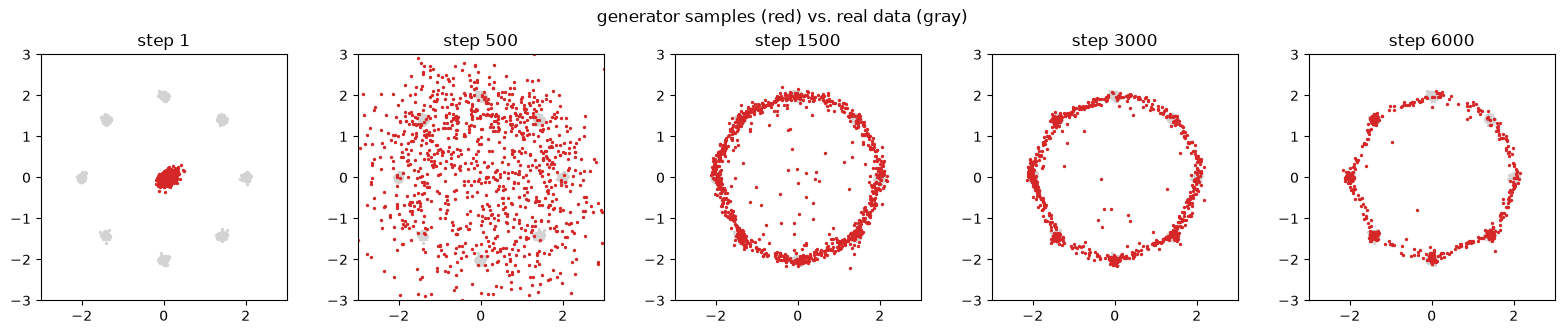

In [4]:
real = real_batch(1000).cpu()
fig, axes = plt.subplots(1, len(snapshots), figsize=(3.2 * len(snapshots), 3.2))
for ax, (s, pts) in zip(axes, snapshots.items()):
    ax.scatter(real[:, 0], real[:, 1], s=2, c="lightgray")
    ax.scatter(pts[:, 0], pts[:, 1], s=2, c="C3")
    ax.set_title(f"step {s}"); ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
plt.suptitle("generator samples (red) vs. real data (gray)"); plt.tight_layout(); plt.show()

## How many modes did we capture?

In [5]:
with torch.no_grad(): s = G(torch.randn(5000, 8, device=device)).cpu()
angles = torch.arange(8) * 2 * math.pi / 8
centers = torch.stack([torch.cos(angles), torch.sin(angles)], 1) * 2
dist = torch.cdist(s, centers)
near = dist.min(1).values < 0.3
counts = torch.bincount(dist.argmin(1)[near], minlength=8)
print("samples per mode:", counts.tolist())
print(f"modes covered: {(counts > 50).sum().item()}/8 | high-quality samples: {near.float().mean():.1%}")

samples per mode: [106, 58, 69, 743, 539, 742, 921, 879]
modes covered: 8/8 | high-quality samples: 81.1%


## Discriminator landscape

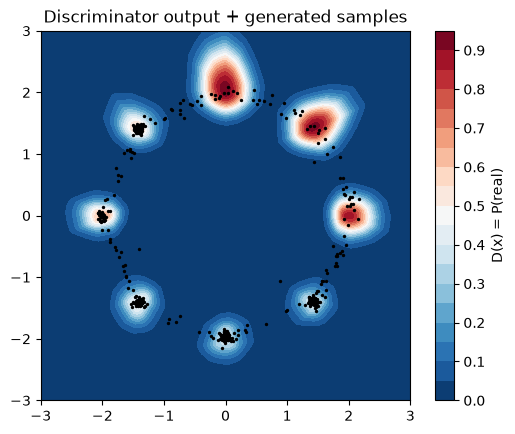

In [6]:
xx, yy = torch.meshgrid(torch.linspace(-3, 3, 200), torch.linspace(-3, 3, 200), indexing="xy")
with torch.no_grad():
    dd = torch.sigmoid(D(torch.stack([xx, yy], -1).view(-1, 2).to(device))).view(200, 200).cpu()
plt.contourf(xx, yy, dd, levels=20, cmap="RdBu_r"); plt.colorbar(label="D(x) = P(real)")
plt.scatter(s[:500, 0], s[:500, 1], s=2, c="k"); plt.gca().set_aspect("equal"); plt.title("Discriminator output + generated samples"); plt.show()

## Takeaways
- Adversarial training produces sharp samples, and GANs (DCGAN, StyleGAN) led image synthesis until about 2021.
- Training is unstable and prone to mode collapse (re-run with other seeds to see it). Diffusion models (2020) and flow matching (2022) later replaced GANs for most generation.